In [1]:
import numpy as np
import matplotlib.pyplot as plt
import h5py

In [2]:
# Activation functions and their derivatives
def sigmoid(Z):
    return 1 / (1 + np.exp(-Z))

def relu(Z):
    return np.maximum(0, Z)

def sigmoid_backward(dA, Z):
    s = sigmoid(Z)
    dZ = dA * s * (1 - s)
    return dZ

def relu_backward(dA, Z):
    dZ = np.array(dA, copy=True) 
    dZ[Z <= 0] = 0 
    return dZ

In [3]:
# Parameter initialization
# Xavier initialization for tanh activation // He initialization for ReLU activation
def deep_initialize_parameters(layer_dims, initialization="he"):
    np.random.seed(3)
    parameters = {}
    L = len(layer_dims)           

    if initialization == "xavier":
        for l in range(1, L):
            parameters['W' + str(l)] = np.random.randn(layer_dims[l], layer_dims[l-1]) * np.sqrt(1 / layer_dims[l-1])
            parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))
    elif initialization == "he":
        for l in range(1, L):
            parameters['W' + str(l)] = np.random.randn(layer_dims[l], layer_dims[l-1]) * np.sqrt(2 / layer_dims[l-1])
            parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))
        
    return parameters

def initialize_parameters(layer_dims, type = "Zeros"):
    np.random.seed(3)
    parameters = {}
    L = len(layer_dims) 
    if type == "Zeros":
        for l in range(1, L):
            parameters['W' + str(l)] = np.zeros((layer_dims[l], layer_dims[l-1]))
            parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))
    elif type == "Ones":
        for l in range(1, L):
            parameters['W' + str(l)] = np.ones((layer_dims[l], layer_dims[l-1])) * 0.01
            parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))
    elif type == "Random":
        for l in range(1, L):
            parameters['W' + str(l)] = np.random.randn(layer_dims[l], layer_dims[l-1]) * 10
            parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))
    elif type == "He":
        for l in range(1, L):
            parameters['W' + str(l)] = np.random.randn(layer_dims[l], layer_dims[l-1]) * np.sqrt(1 / layer_dims[l-1])
            parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))
        
    return parameters

In [4]:
# Forward propagation functions
def linear_forward(A_prev, W, b):
    Z = np.dot(W, A_prev) + b
    cache = (A_prev, W, b)
    return Z, cache

def linear_activation_forward(A_prev, W, b, activation):
    if activation == "sigmoid":
        Z, linear_cache = linear_forward(A_prev, W, b)
        A = sigmoid(Z)
        activation_cache = Z
    elif activation == "relu":
        Z, linear_cache = linear_forward(A_prev, W, b)
        A = relu(Z)
        activation_cache = Z
    cache = (linear_cache, activation_cache)
    return A, cache

def L_model_forward(X, parameters):
    caches = []
    A = X
    L = len(parameters) // 2
    for l in range(1, L):
        A_prev = A
        A, cache = linear_activation_forward(A_prev, parameters['W' + str(l)], parameters['b' + str(l)], activation="relu")
        caches.append(cache)
    AL, cache = linear_activation_forward(A, parameters['W' + str(L)], parameters['b' + str(L)], activation="sigmoid")
    caches.append(cache)
    return AL, caches


In [5]:
# Cost function
def compute_cost(AL, Y, parameters, lambd=0.1 ):
    m = Y.shape[1]
    reg_cost = [np.sum(np.square(parameters['W' + str(l)])) for l in range(1, len(parameters)//2 + 1)]
    cost = - np.sum(Y * np.log(AL) + (1 - Y) * np.log(1 - AL)) / m + (lambd / (2 * m)) * np.sum(reg_cost)
    cost = np.squeeze(cost)
    return cost

In [6]:

def linear_backward(dZ, cache, lambd=0.1):
    A_prev, W, b = cache
    m = A_prev.shape[1]
    dW = np.dot(dZ, A_prev.T) / m + (lambd / m) * W
    db = np.sum(dZ, axis = 1, keepdims = True) / m
    dA_prev = np.dot(W.T, dZ)
    return dA_prev, dW, db

def linear_activation_backward(dA, cache, activation, lambd=0.1):

    linear_cache, activation_cache = cache

    if activation == "relu":
        dZ = relu_backward(dA, activation_cache)
        dA_prev, dW, db = linear_backward(dZ, linear_cache, lambd) 

    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, activation_cache)
        dA_prev, dW, db = linear_backward(dZ, linear_cache)

    return dA_prev, dW, db

def L_model_backward(AL, Y, caches, lambd=0.1):
    grads = {}
    L = len(caches)
    m = AL.shape[1]
    Y = Y.reshape(AL.shape)
    dAL = - (np.divide(Y, AL) - np.divide(1 - Y, 1 - AL))
    current_cache = caches[L - 1]
    grads["dA" + str(L - 1)], grads["dW" + str(L)], grads["db" + str(L)] = linear_activation_backward(dAL, current_cache, activation="sigmoid", lambd=lambd)
    for l in reversed(range(L - 1)):
        current_cache = caches[l]
        dA_prev_temp, dW_temp, db_temp = linear_activation_backward(grads["dA" + str(l + 1)], current_cache, activation = "relu")
        grads["dA" + str(l)] = dA_prev_temp
        grads["dW" + str(l + 1)] = dW_temp
        grads["db" + str(l + 1)] = db_temp
    return grads


In [7]:
def update_parameters(parameters, grads, learning_rate):
    L = len(parameters) // 2
    for l in range(1, L + 1):
        parameters["W" + str(l)] -= learning_rate * grads["dW" + str(l)]
        parameters["b" + str(l)] -= learning_rate * grads["db" + str(l)]
        
    return parameters

Number of training examples: 209
Number of test examples: 50
train_set_x shape: (209, 64, 64, 3)
train_set_y shape: (1, 209)
test_set_x shape: (50, 64, 64, 3)
test_set_y shape: (1, 50)


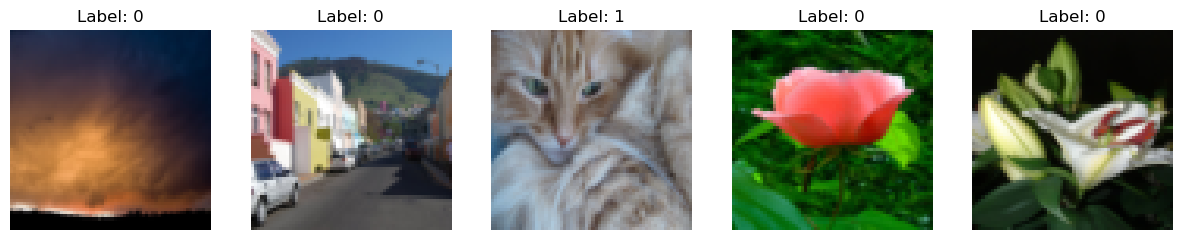

In [8]:
# Example usage:
def load_data():
    train_dataset = h5py.File('datasets/train_catvnoncat.h5', "r")
    train_set_x_orig = np.array(train_dataset["train_set_x"][:]) # your train set features
    train_set_y_orig = np.array(train_dataset["train_set_y"][:]) # your train set labels

    test_dataset = h5py.File('datasets/test_catvnoncat.h5', "r")
    test_set_x_orig = np.array(test_dataset["test_set_x"][:]) # your test set features
    test_set_y_orig = np.array(test_dataset["test_set_y"][:]) # your test set labels

    classes = np.array(test_dataset["list_classes"][:]) # the list of classes
    
    train_set_y_orig = train_set_y_orig.reshape((1, train_set_y_orig.shape[0]))
    test_set_y_orig = test_set_y_orig.reshape((1, test_set_y_orig.shape[0]))
    
    return train_set_x_orig, train_set_y_orig, test_set_x_orig, test_set_y_orig, classes

train_set_x_orig, train_set_y_orig, test_set_x_orig, test_set_y_orig, classes = load_data()

print("Number of training examples: " + str(train_set_x_orig.shape[0]))
print("Number of test examples: " + str(test_set_x_orig.shape[0]))
print("train_set_x shape: " + str(train_set_x_orig.shape))
print("train_set_y shape: " + str(train_set_y_orig.shape))
print("test_set_x shape: " + str(test_set_x_orig.shape))
print("test_set_y shape: " + str(test_set_y_orig.shape))

fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    ax[i].imshow(train_set_x_orig[i])
    ax[i].set_title("Label: " + str(train_set_y_orig[0, i]))
    ax[i].axis('off')

In [9]:
train_set_x = train_set_x_orig.reshape(train_set_x_orig.shape[0], -1).T / 255.
test_set_x = test_set_x_orig.reshape(test_set_x_orig.shape[0], -1).T / 255.
print("train_set_x shape: " + str(train_set_x.shape))

layers_dims = [12288, 20, 7, 5, 1] # 4-layer model

train_set_x shape: (12288, 209)


In [10]:
def mini_batch(batch_size, X, Y):
    m = X.shape[1]
    permutation = list(np.random.permutation(m))
    shuffled_X = X[:, permutation]
    shuffled_Y = Y[:, permutation].reshape((1, m))
    
    mini_batches = []
    num_complete_minibatches = m // batch_size
    for k in range(num_complete_minibatches):
        mini_batch_X = shuffled_X[:, k * batch_size : (k + 1) * batch_size]
        mini_batch_Y = shuffled_Y[:, k * batch_size : (k + 1) * batch_size]
        mini_batches.append((mini_batch_X, mini_batch_Y))
    
    if m % batch_size != 0:
        mini_batch_X = shuffled_X[:, num_complete_minibatches * batch_size : m]
        mini_batch_Y = shuffled_Y[:, num_complete_minibatches * batch_size : m]
        mini_batches.append((mini_batch_X, mini_batch_Y))
    
    return mini_batches

In [ ]:
def model_train(X, X_val, Y, Y_val, layer_dims, learning_rate=0.001, lambd=0.1, batch_size=64, num_iterations=2500, print_cost=False):
    np.random.seed(1)
    costs = []
    val_costs = []
    parameters = deep_initialize_parameters(layer_dims)

    for i in range(0, num_iterations):
        epoch_costs = []
        
        for mini_batch_X, mini_batch_Y in mini_batch(batch_size, X, Y):
            AL, caches = L_model_forward(mini_batch_X, parameters)
            cost = compute_cost(AL, mini_batch_Y, parameters, lambd)
            epoch_costs.append(cost)
            grads = L_model_backward(AL, mini_batch_Y, caches, lambd)
            parameters = update_parameters(parameters, grads, learning_rate)
        
        if print_cost and i % 100 == 0:

            epoch_cost = np.mean(epoch_costs)
            costs.append(epoch_cost)
            
            
            val_AL, _ = L_model_forward(X_val, parameters)
            val_epoch_cost = compute_cost(val_AL, Y_val, parameters, lambd)
            val_costs.append(val_epoch_cost)
            
            val_costs.append(val_epoch_cost)
            
            print(f"Cost after iteration {i}: {epoch_cost:.6f}")
            print(f"Validation Cost after iteration {i}: {val_epoch_cost:.6f}")
    
    # Plotting
    plt.figure(figsize=(10, 6))
    plt.plot(np.squeeze(costs), label='Training cost')
    plt.plot(np.squeeze(val_costs), label='Validation cost')
    plt.legend()
    plt.ylabel('cost')
    plt.xlabel('iterations (per hundreds)')
    plt.title(f"Learning rate = {learning_rate}")
    plt.show()
    
    return parameters

parameters = model_train(
    train_set_x, test_set_x, train_set_y_orig, test_set_y_orig,
    layers_dims, learning_rate= 0.003, lambd= 20, batch_size=32,
    num_iterations=3500, print_cost=True
    )

Cost after iteration 0: 23.570720
Validation Cost after iteration 0: 13.667126
Cost after iteration 100: 23.226208
Validation Cost after iteration 100: 13.522690
Cost after iteration 200: 23.220980
Validation Cost after iteration 200: 13.592485
Cost after iteration 300: 23.613159
Validation Cost after iteration 300: 13.864823
Cost after iteration 400: 23.955818
Validation Cost after iteration 400: 14.194109


In [37]:
def predict(X, Y, parameters):
    AL, _ = L_model_forward(X, parameters)
    predictions = (AL > 0.5)
    print("Accuracy: "  + str(np.mean(predictions == Y)))
    return predictions

predictions_train = predict(train_set_x, train_set_y_orig, parameters)

Accuracy: 1.0


In [38]:
predictions = predict(test_set_x, test_set_y_orig, parameters)

Accuracy: 0.72


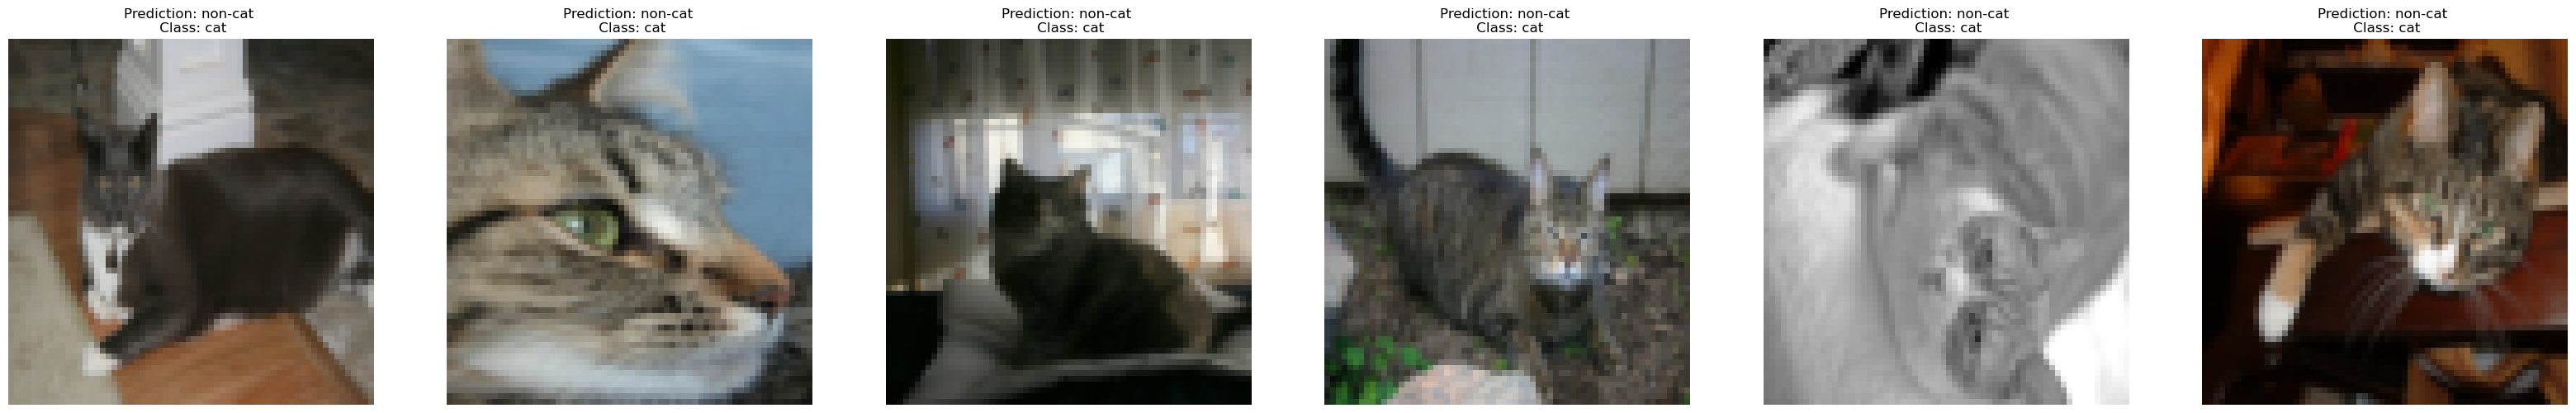

In [14]:
def print_mislabeled_images(classes, X, y, p):

    a = p + y
    mislabeled_indices = np.asarray(np.where(a == 1))
    plt.rcParams['figure.figsize'] = (40.0, 40.0)
    num_images = len(mislabeled_indices[0])
    for i in range(num_images):
        index = mislabeled_indices[1][i]
        
        plt.subplot(2, num_images, i + 1)
        plt.imshow(X[:,index].reshape(64,64,3), interpolation='nearest')
        plt.axis('off')
        plt.title("Prediction: " + classes[int(p[0,index])].decode("utf-8") + " \n Class: " + classes[y[0,index]].decode("utf-8"))

print_mislabeled_images(classes, train_set_x, train_set_y_orig, predictions_train)